# BudgetBuddy: Expense Categorizer 🏷️
**من الصفر، خطوة خطوة** (مبني على مادة COE305 Machine Learning)

**المهمة:** الطالب بيكتب وصف المصروف ("شاورما"، "İstanbulkart dolum"، "netflix")، والموديل لازم يختار الفئة.

بلغة Week 1: **Task T** = تصنيف وصف المصروف لفئة من 8 · **Performance P** = accuracy و macro-F1 · **Experience E** = أمثلة مصنّفة.

هاد **Supervised Learning → Classification → Multi-class** (8 فئات)، لأنه عنا أمثلة مع الجواب الصح (labels).

### خطة الـ notebook (نفس الـ ML workflow من Week 1)
| # | الخطوة | المحاضرة |
|---|---|---|
| 1 | جمع البيانات + EDA | Week 1, 4 |
| 2 | Preprocessing للنص + تحويله لأرقام | Week 4 + جديد |
| 3 | Naive Bayes **من الصفر** | Week 8 |
| 4 | مقارنة مع موديلات تانية + Cross-validation | Week 3, 7, 8 |
| 5 | Hyperparameter tuning | Week 9 |
| 6 | Explainability | Week 10 |

## الخطوة 1: البيانات و EDA

### من وين جت البيانات؟
تطبيق جديد = **ما في مستخدمين = ما في بيانات**. هاي اسمها مشكلة **Cold Start**.
الحل: كتبنا **seed dataset** بإيدنا (`data/seed_examples.py`): أمثلة حقيقية بالثلاث لغات، بأسماء محلات تركيا (Migros, BİM, Getir)، وفيها أخطاء إملائية متعمدة ("netflx") لأنه هيك بيكتبوا الناس.

لاحقاً، **كل مرة الطالب بيختار أو بيصحح فئة = مثال جديد**، فالبيانات بتكبر مع الاستخدام.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# App colours, so the charts look like BudgetBuddy
PINE, MUTED, BERRY = "#1e6b57", "#9aa8a3", "#b23c63"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

df = pd.read_csv("../data/expenses.csv")
df = df[df["source"] == "round1"].drop(columns="source")   # steps 1-3: the first round of data
print("Shape:", df.shape)       # (rows, columns)
print(df.sample(8, random_state=42).to_string(index=False))

Shape: (448, 3)
description  category language
       zara  shopping       en
      watch  shopping       en
 bus ticket transport       en
    glasses    health       en
         مي      food       ar
     bakery      food       en
   coursera     study       en
  بيض وجبنة      food       ar


### Data Cleaning: المكرر (Week 4 + مشروعك: *"Removed duplicates"*)
أسماء ماركات متل `spotify` و `zara` موجودة بالإنجليزي والتركي **بنفس الكتابة**.
ليش هاد مشكلة؟ لو نفس النص وقع مرة بالـ train ومرة بالـ test، الموديل **شافه قبل** → الـ accuracy بتطلع أعلى من الحقيقة. هاد اسمه **Data Leakage**.

In [2]:
print("Missing values:\n", df.isna().sum().to_string(), "\n")

dupes = df[df.duplicated("description", keep=False)].sort_values("description")
print(f"Duplicated descriptions: {df.duplicated('description').sum()}")
print(dupes.to_string(index=False), "\n")

df = df.drop_duplicates("description").reset_index(drop=True)
print("After removing duplicates:", df.shape)

Missing values:
 description    0
category       0
language       0 

Duplicated descriptions: 9
description      category language
    bitaksi     transport       en
    bitaksi     transport       tr
    bowling entertainment       en
    bowling entertainment       tr
    havaist     transport       en
    havaist     transport       tr
hepsiburada      shopping       tr
hepsiburada      shopping       en
 lc waikiki      shopping       tr
 lc waikiki      shopping       en
      metro     transport       en
      metro     transport       tr
    spotify entertainment       tr
    spotify entertainment       en
   vodafone         bills       en
   vodafone         bills       tr
       zara      shopping       tr
       zara      shopping       en 

After removing duplicates: (439, 3)


### توزيع الفئات: هل البيانات متوازنة؟ (Week 5: Imbalanced data)

category
food             115
transport         59
shopping          59
study             50
entertainment     48
health            42
bills             41
other             25

Imbalance ratio (largest / smallest): 4.6 : 1


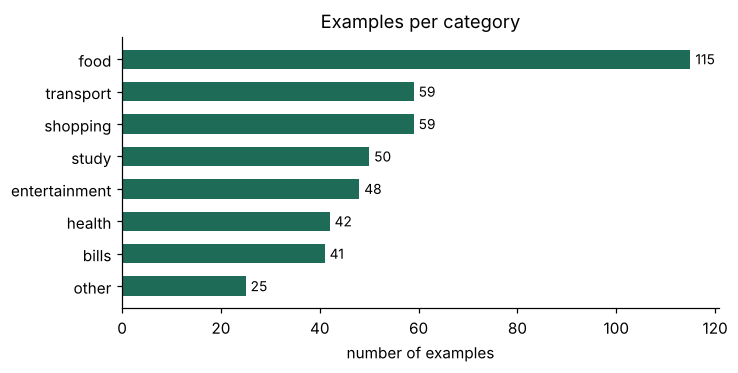

In [3]:
counts = df["category"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(counts.index[::-1], counts.values[::-1], color=PINE, height=0.6)
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 1, y, str(v), va="center", fontsize=9)
ax.set_title("Examples per category")
ax.set_xlabel("number of examples")

ratio = counts.max() / counts.min()
print(counts.to_string())
print(f"\nImbalance ratio (largest / smallest): {ratio:.1f} : 1")

**ملاحظة:** `food` أكبر فئة بفرق واضح، و`other` أصغر وحدة: النسبة تقريباً **4.6 : 1**.
هاد **متعمّد**، لأنه بالحياة الحقيقية الأكل أكثر مصروف متكرر.

**شو يعني هاد لبعدين؟**
- الـ **Accuracy** لحالها ممكن تكذب: موديل بيقول دايماً "food" رح ياخد ~25% بدون ما يتعلم شي → رح نستخدم كمان **macro-F1** (Week 9) اللي بتعطي كل فئة نفس الوزن.
- لما نقسم البيانات لازم نستخدم **Stratified split** (Week 7) لحتى كل جزء فيه نفس نسب الفئات.
- **ما رح نستخدم SMOTE** (Week 5): SMOTE بيخلق نقاط بين نقطتين بالأرقام، وهاد ما إله معنى مع النصوص (شو يعني "نص بين شاورما وتكسي"؟).

language       ar  en  tr
category                 
other           8   9   8
bills          14  15  12
health         14  15  13
entertainment  16  20  12
study          16  20  14
shopping       18  24  17
transport      19  25  15
food           38  43  34


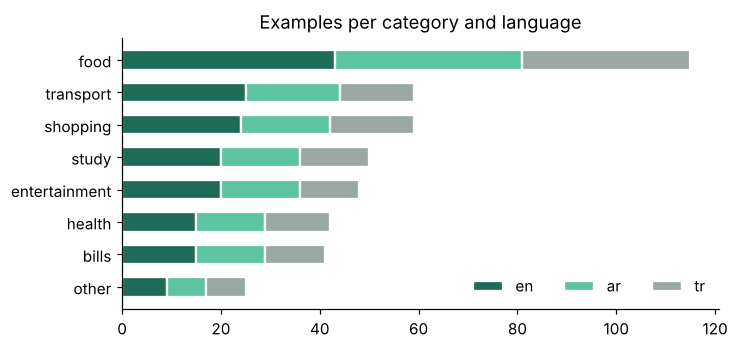

In [4]:
langs = pd.crosstab(df["category"], df["language"]).loc[counts.index[::-1]]  # same order as above
fig, ax = plt.subplots(figsize=(7, 3.2))
left = None
colors = {"en": PINE, "ar": "#5cc4a0", "tr": MUTED}
bottom = pd.Series(0, index=langs.index)
for lang in ["en", "ar", "tr"]:
    ax.barh(langs.index, langs[lang], left=bottom, color=colors[lang], height=0.6, label=lang, edgecolor="white", linewidth=1.5)
    bottom += langs[lang]
ax.legend(frameon=False, ncol=3, loc="lower right")
ax.set_title("Examples per category and language")
print(langs.to_string())

### طول النصوص
النصوص **قصيرة جداً**: هاد بيأثر على اختيار الطريقة. ما في جمل طويلة ولا سياق، فكل كلمة (وحتى كل جزء من كلمة) مهم.

       n_words  n_chars
count    439.0    439.0
mean       1.6      9.2
std        0.7      4.2
min        1.0      2.0
25%        1.0      6.0
50%        1.0      9.0
75%        2.0     12.0
max        5.0     22.0


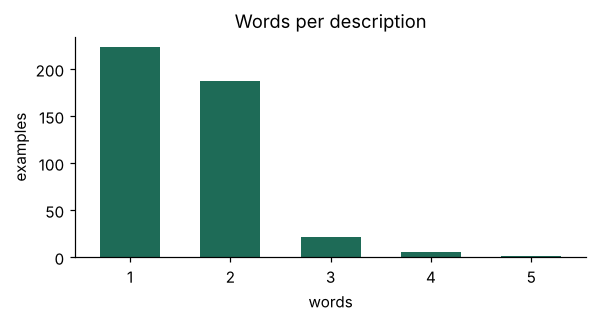

In [5]:
df["n_words"] = df["description"].str.split().str.len()
df["n_chars"] = df["description"].str.len()
print(df[["n_words", "n_chars"]].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 2.6))
df["n_words"].value_counts().sort_index().plot.bar(ax=ax, color=PINE, width=0.6)
ax.set_title("Words per description")
ax.set_xlabel("words"); ax.set_ylabel("examples")
ax.tick_params(axis="x", rotation=0)

### خلاصة الخطوة 1
| ملاحظة | شو منعمل فيها |
|---|---|
| 448 مثال → **439** بعد حذف المكرر | منتجنب Data Leakage |
| 8 فئات، **غير متوازنة** (4.6:1) | macro-F1 + Stratified K-Fold |
| 3 لغات بحروف مختلفة (لاتيني + عربي) | الـ preprocessing لازم يفهم الاتنين |
| النصوص **قصيرة** (1-3 كلمات غالباً) | منستخدم أجزاء الكلمات كمان (character n-grams) بالخطوة 2 |
| أخطاء إملائية ("shawrma", "netflx") | character n-grams بتساعد هون كمان |

**الخطوة الجاية:** الموديل ما بيفهم كلمات، بيفهم **أرقام**. كيف نحوّل "شاورما" لأرقام؟

---
## الخطوة 2: من نص لأرقام 🔢

الموديل عبارة عن معادلات رياضية، فما بيقدر يتعامل مع كلمة "شاورما". لازم نحوّل كل وصف لـ **vector** (صف أرقام).
بمشروعك كانت البيانات أصلاً أرقام (GDP، Life expectancy)، أما هون عنا **نص**. هاد الجزء الجديد.

### 2.1 Preprocessing: توحيد الكتابة
نفس الكلمة ممكن تنكتب بطرق مختلفة. الكود بـ `backend/app/ml/text.py`، ونفس الملف بيستخدمه **السيرفر** وقت التنبؤ (منتجنب *training-serving skew*).

In [6]:
import sys
sys.path.insert(0, "../../backend")     # use the exact code the API uses
from app.ml.text import normalize, words, char_ngrams, features

examples = ["Döner  KEBAP!", "doner kebap", "قَهوةٌ", "قهوة", "إيجار", "ايجار",
            "İstanbulkart DOLUM", "Netflix (2 months) 150TL", "H&M"]
for text in examples:
    print(f"{text!r:30} -> {normalize(text)!r}")

'Döner  KEBAP!'                -> 'doner kebap'
'doner kebap'                  -> 'doner kebap'
'قَهوةٌ'                       -> 'قهوه'
'قهوة'                         -> 'قهوه'
'إيجار'                        -> 'ايجار'
'ايجار'                        -> 'ايجار'
'İstanbulkart DOLUM'           -> 'istanbulkart dolum'
'Netflix (2 months) 150TL'     -> 'netflix months tl'
'H&M'                          -> 'h&m'


| القاعدة | ليش |
|---|---|
| حروف صغيرة، و `İ` التركية → `i` | `Migros` = `migros` |
| العربي: أ إ آ → ا، ة → ه، ى → ي، وحذف التشكيل | `إيجار` = `ايجار`، و `قَهوةٌ` = `قهوة` |
| التركي: ö→o، ş→s، ı→i... | الطلاب بيكتبوا `doner` بقد ما بيكتبوا `döner` |
| حذف الأرقام | "150TL" ما بتحكي شي عن الفئة |
| حذف الرموز (إلا `&`) | `H&M` ماركة |

### 2.2 Bag of Words: منعدّ الكلمات
الفكرة بسيطة: منعمل **قاموس** (vocabulary) فيه كل كلمة شفناها، وكل وصف بيصير صف فيه **قديش تكررت كل كلمة**.
ترتيب الكلمات بيضيع (لهيك "كيس كلمات")، بس بأوصاف من كلمة أو كلمتين هاد ما بيفرق.

خلينا نبنيه **بإيدنا** على 4 أمثلة:

In [7]:
import numpy as np

docs = ["coffee", "coffee with friends", "taxi with friends", "taxi home with friends", "pizza with friends"]
tokenized = [words(d) for d in docs]

vocab = sorted({w for doc in tokenized for w in doc})        # every distinct word
index = {w: i for i, w in enumerate(vocab)}

bow = np.zeros((len(docs), len(vocab)), dtype=int)          # rows = documents, columns = words
for row, doc in enumerate(tokenized):
    for w in doc:
        bow[row, index[w]] += 1

print(pd.DataFrame(bow, index=docs, columns=vocab).to_string())

                        coffee  friends  home  pizza  taxi  with
coffee                       1        0     0      0     0     0
coffee with friends          1        1     0      0     0     1
taxi with friends            0        1     0      0     1     1
taxi home with friends       0        1     1      0     1     1
pizza with friends           0        1     0      1     0     1


### 2.3 TF-IDF: مش كل الكلمات إلها نفس الأهمية
بالجدول فوق، `with` و `friends` إلهم نفس وزن `coffee` و `taxi`. بس `with` موجودة بأوصاف كتير ومن فئات مختلفة، فما بتساعد نفرّق.

**TF-IDF = TF × IDF**
- **TF** (Term Frequency): قديش الكلمة موجودة **بهالوصف**
- **IDF** (Inverse Document Frequency): قديش الكلمة **نادرة** بكل البيانات

$$\text{idf}(t) = \ln\frac{1 + N}{1 + \text{df}(t)} + 1$$

حيث N عدد الأوصاف، و df(t) بكم وصف ظهرت الكلمة. كلمة بكل الأوصاف ← idf صغير. كلمة نادرة ← idf كبير.
بعدين منقسم كل صف على طوله (**L2 normalization**) لحتى الأوصاف الطويلة ما تاخد أرقام أكبر بس لأنها أطول. هاد نفس فكرة **Feature Scaling** بـ Week 4.

In [8]:
def tfidf_from_scratch(counts):
    n_docs = counts.shape[0]
    df_t = (counts > 0).sum(axis=0)                     # in how many documents each word appears
    idf = np.log((1 + n_docs) / (1 + df_t)) + 1         # rare words -> bigger weight
    weighted = counts * idf
    norms = np.linalg.norm(weighted, axis=1, keepdims=True)
    return weighted / norms, idf

ours, idf = tfidf_from_scratch(bow)
print("IDF per word:")
print(pd.Series(idf, index=vocab).round(3).to_string(), "\n")
print(pd.DataFrame(ours, index=docs, columns=vocab).round(3).to_string())

IDF per word:
coffee     1.693
friends    1.182
home       2.099
pizza      2.099
taxi       1.693
with       1.182 

                        coffee  friends   home  pizza   taxi   with
coffee                   1.000    0.000  0.000  0.000  0.000  0.000
coffee with friends      0.712    0.497  0.000  0.000  0.000  0.497
taxi with friends        0.000    0.497  0.000  0.000  0.712  0.497
taxi home with friends   0.000    0.373  0.661  0.000  0.534  0.373
pizza with friends       0.000    0.441  0.000  0.782  0.000  0.441


`with` و `friends` موجودين بـ 4 من 5 أوصاف، فأخدوا **أصغر وزن** (idf ≈ 1.18). أما `coffee` و `taxi` (بوصفين) و `home` و `pizza` (بوصف واحد) أخدوا وزن أكبر.
مثلاً بـ "coffee with friends": وزن `coffee` أكبر من وزن `with`، يعني الموديل رح يركّز على الكلمة اللي فعلاً بتحكي شو المصروف. هاد بالضبط اللي بدنا ياه.

**هل الكود تبعنا صح؟** منقارنه مع scikit-learn، المكتبة اللي الكل بيستخدمها. إذا طلع نفس الأرقام بالضبط، فهمنا الطريقة صح:

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

sk = TfidfVectorizer(analyzer=words)          # same tokens as ours
sk_matrix = sk.fit_transform(docs).toarray()
print("Same vocabulary:", list(sk.get_feature_names_out()) == vocab)
print("Same numbers:   ", np.allclose(ours, sk_matrix))

Same vocabulary: True
Same numbers:    True


✅ **نفس النتيجة بالضبط.** هلأ منعرف شو بيصير جوّا `TfidfVectorizer`، مش بس كيف نستدعيه.

### 2.4 المشكلة: كلمة ما شافها قبل
الكلمات الكاملة إلها نقطة ضعف كبيرة: **أي كلمة جديدة أو غلطة إملائية = أصفار**.
الموديل شاف `shawarma`، والطالب كتب `shawrma`. بالنسبة لـ Bag of Words، هدول كلمتين **ما إلهم علاقة ببعض أبداً**.

الحل: **Character n-grams**، يعني منقسم الكلمة لقطع من 2 و3 و4 حروف:

In [10]:
print("shawarma ->", char_ngrams("shawarma", sizes=(3,)))
print("shawrma  ->", char_ngrams("shawrma", sizes=(3,)))

def cosine(a, b):
    a, b = set(a), set(b)
    return len(a & b) / np.sqrt(len(a) * len(b)) if a and b else 0.0

pairs = [("shawarma", "shawrma"), ("netflix", "netflx"), ("döner", "doner kebap"),
         ("kitap", "kitapçı"), ("قهوة", "قهوة مع الاصحاب"), ("taxi", "shawarma")]
print(f"\n{'pair':34} {'words only':>10} {'+ char n-grams':>15}")
for a, b in pairs:
    print(f"{a + '  vs  ' + b:34} {cosine(words(a), words(b)):>10.2f} {cosine(features(a), features(b)):>15.2f}")

shawarma -> [' sh', 'sha', 'haw', 'awa', 'war', 'arm', 'rma', 'ma ']
shawrma  -> [' sh', 'sha', 'haw', 'awr', 'wrm', 'rma', 'ma ']

pair                               words only  + char n-grams
shawarma  vs  shawrma                    0.00            0.64
netflix  vs  netflx                      0.00            0.64
döner  vs  doner kebap                   0.71            0.71
kitap  vs  kitapçı                       0.00            0.64
قهوة  vs  قهوة مع الاصحاب                0.58            0.56
taxi  vs  shawarma                       0.00            0.00


**الفرق واضح:**
- `shawarma` و `shawrma`: بالكلمات **0** (ما إلهم علاقة)، وبالقطع **عالي** ← الموديل رح يعرف إنهم نفس الشي
- `kitap` (كتاب) و `kitapçı` (مكتبة): بيشتركوا بالجذر
- `taxi` و `shawarma`: قريب من الصفر بالطريقتين ✅ (ما في علاقة فعلاً)

ونفس الشي بيساعد بالعربي، لأنه الكلمة بتتغير بالسوابق واللواحق (ال، ات، ه).

### 2.5 الـ features النهائية
كل وصف = **الكلمات الكاملة** (`w:kahve`) + **قطع الحروف** (` ka`، `kah`...):

In [11]:
print(features("Kahve"))

all_features = TfidfVectorizer(analyzer=features).fit(df["description"])
X = all_features.transform(df["description"])
print(f"\nDescriptions: {X.shape[0]}   ·   Distinct features (columns): {X.shape[1]:,}")
print(f"Non-zero cells: {X.nnz:,} of {X.shape[0] * X.shape[1]:,} = {100 * X.nnz / (X.shape[0] * X.shape[1]):.2f}%")

['w:kahve', ' k', 'ka', 'ah', 'hv', 've', 'e ', ' ka', 'kah', 'ahv', 'hve', 've ', ' kah', 'kahv', 'ahve', 'hve ']

Descriptions: 439   ·   Distinct features (columns): 5,408
Non-zero cells: 11,962 of 2,374,112 = 0.50%


### 2.6 Curse of Dimensionality؟ (Week 12)
عنا **أعمدة أكثر بكتير من الصفوف**، و **أكثر من 99% من الخانات أصفار** (sparse matrix).
بـ Week 12 تعلمنا إنه الأبعاد الكتيرة مشكلة، خصوصاً لـ **KNN** لأنه بيعتمد على المسافات، ومع أبعاد كتيرة كل النقاط بتصير "بعيدة".

بس موديلات متل **Naive Bayes** و **Logistic Regression** و **Linear SVM** بتشتغل منيح جداً مع هيك بيانات، لأنها بتتعامل مع كل feature لحالها تقريباً. رح نشوف هاد بالأرقام بالخطوة 4.

### خلاصة الخطوة 2
| شو عملنا | ليش |
|---|---|
| `normalize()`: توحيد الكتابة بالثلاث لغات | نفس الكلمة = نفس الـ feature |
| Bag of Words **من الصفر** | فهمنا كيف النص بيصير أرقام |
| TF-IDF **من الصفر**، وطابق scikit-learn 100% | الكلمات النادرة أهم |
| Character n-grams | الأخطاء الإملائية والكلمات المشتقة |
| نفس الكود بالسيرفر | منتجنب training-serving skew |

**الخطوة الجاية:** **Naive Bayes من الصفر** باستخدام Bayes' theorem من Week 8.

---
## الخطوة 3: Naive Bayes من الصفر 🧠 (Week 8)

### الفكرة
بدنا نعرف: **شو احتمال إنه المصروف "food"، إذا الوصف "coffee and cake"؟**

$$P(c \mid d) = \frac{P(d \mid c)\, P(c)}{P(d)}$$

| الرمز | الاسم (Week 8) | بمثالنا |
|---|---|---|
| $P(c)$ | **Prior** | قديش الفئة شائعة؟ (الأكل شائع، "other" نادر) |
| $P(d \mid c)$ | **Likelihood** | إذا المصروف أكل، قديش متوقع نشوف هالكلمات؟ |
| $P(c \mid d)$ | **Posterior** | الجواب اللي بدنا ياه |
| $P(d)$ | Evidence | نفسه لكل الفئات، فمنتجاهله لما نقارن |

**ليش "Naive"؟** منفترض إنه كل كلمة مستقلة عن الباقي (متل Outlook و Temperature بمثال الطقس بـ Week 8):

$$P(\text{"coffee and cake"} \mid \text{food}) \approx P(\text{coffee}\mid\text{food}) \times P(\text{and}\mid\text{food}) \times P(\text{cake}\mid\text{food})$$

### 3.1 خلينا نحسبها بإيدنا على مثال صغير

In [12]:
import math
from collections import Counter

train = [("coffee", "food"), ("coffee and cake", "food"), ("cake", "food"),
         ("bus ticket", "transport"), ("taxi", "transport"), ("bus", "transport")]

docs_per_class = Counter(label for _, label in train)
words_per_class = {c: Counter() for c in docs_per_class}
for text, label in train:
    words_per_class[label].update(text.split())
vocab = {w for counts in words_per_class.values() for w in counts}

print("Prior P(c):", {c: f"{n}/{len(train)}" for c, n in docs_per_class.items()})
for c, counts in words_per_class.items():
    print(f"Words in {c:9}: {dict(counts)}  (total {sum(counts.values())})")
print("Vocabulary:", sorted(vocab), f"-> |V| = {len(vocab)}")

Prior P(c): {'food': '3/6', 'transport': '3/6'}
Words in food     : {'coffee': 2, 'and': 1, 'cake': 2}  (total 5)
Words in transport: {'bus': 2, 'ticket': 1, 'taxi': 1}  (total 4)
Vocabulary: ['and', 'bus', 'cake', 'coffee', 'taxi', 'ticket'] -> |V| = 6


**مشكلة الصفر (Zero-frequency):** كلمة `ticket` ما ظهرت ولا مرة بـ `food`، يعني $P(\text{ticket}\mid\text{food}) = 0$.
وبما إنه منضرب الاحتمالات ببعض، **صفر واحد بيصفّر كل شي**، حتى لو باقي الكلمات بتقول "أكل" بقوة.

**الحل: Laplace smoothing**: منزيد **1** (اسمه α) على كل عدّ:

$$P(w \mid c) = \frac{\text{count}(w, c) + \alpha}{\text{total words in } c + \alpha \cdot |V|}$$

In [13]:
def p_word(word, c, alpha=1):
    return (words_per_class[c][word] + alpha) / (sum(words_per_class[c].values()) + alpha * len(vocab))

text = "coffee ticket"
for c in docs_per_class:
    prior = docs_per_class[c] / len(train)
    terms = [p_word(w, c) for w in text.split()]
    score = prior * math.prod(terms)
    print(f"{c:9}: P(c)={prior:.3f} × " + " × ".join(f"P({w}|c)={p:.3f}" for w, p in zip(text.split(), terms))
          + f"  =  {score:.5f}")

food     : P(c)=0.500 × P(coffee|c)=0.273 × P(ticket|c)=0.091  =  0.01240
transport: P(c)=0.500 × P(coffee|c)=0.100 × P(ticket|c)=0.200  =  0.01000


الأرقام صغيرة كتير. مع 3 كلمات ماشي الحال، بس الموديل الحقيقي بيشوف **عشرات الـ features** لكل وصف (كلمات + قطع حروف)،
وضرب أرقام صغيرة كتير بيوصل لـ **0.0** بالكمبيوتر (اسمها **underflow**):

In [14]:
p = 0.001
print("0.001 multiplied 120 times:", p ** 120)          # the float gives up: 0.0
print("the same with logs:        ", 120 * math.log(p))  # log(a*b) = log(a) + log(b): no problem

0.001 multiplied 120 times: 0.0
the same with logs:         -828.9306334778564


فبدل ما نضرب احتمالات، **منجمع logs**. وبالآخر منرجّعهم لاحتمالات مجموعها 1 (اسمها **softmax**).

### 3.2 الموديل الحقيقي: `backend/app/ml/naive_bayes.py`
كتبناه **بايثون عادي بدون numpy**، لأنه نفس الملف رح يشتغل بالسيرفر. أهم 3 أجزاء:
```python
def learn(self, text, label):              # التدريب = عدّ بس!
    found = self.featurize(text)
    self.doc_counts[label] += 1            # للـ prior
    self.feature_counts[label].update(found)   # للـ likelihood

def log_scores(self, text):
    score = log(P(c))                       # prior
    for f in features:                      # + log likelihood لكل feature
        score += log((count(f, c) + α) / (total_c + α·|V|))
```
**ملاحظة مهمة:** بما إنه التدريب = عدّ، فينا نعلّم الموديل مثال واحد كمان (`learn`) **بدون ما نعيد التدريب من الأول**. هاد رح نستخدمه لما الطالب يصحح فئة.

In [15]:
from sklearn.model_selection import train_test_split
from app.ml.naive_bayes import NaiveBayes

# 80% train / 20% test, stratified: same category proportions in both (Week 7)
X_train, X_test, y_train, y_test = train_test_split(
    df["description"], df["category"], test_size=0.2, stratify=df["category"], random_state=42)
print(f"train: {len(X_train)}   test: {len(X_test)}")

model = NaiveBayes(alpha=1.0).fit(X_train, y_train)
print(f"learned {len(model.vocabulary):,} distinct features")

for text in ["shawrma", "uber to the airport", "دفعت فاتورة الكهربا", "spor salonu"]:
    p = model.predict(text)
    print(f"{text:22} -> {p.label:10} ({p.confidence:.0%})")

train: 351   test: 88
learned 4,668 distinct features
shawrma                -> food       (100%)
uber to the airport    -> transport  (100%)
دفعت فاتورة الكهربا    -> bills      (100%)
spor salonu            -> health     (100%)


**لاحظ الـ 100%:** الموديل "متأكد" بشكل مبالغ فيه. هاد عيب معروف بـ Naive Bayes: الـ features **مش مستقلة** فعلياً
(القطع ` sh` و `sha` و `shaw` كلها جاية من نفس الكلمة)، والموديل بيحسب نفس الدليل كذا مرة، فبيصير واثق زيادة عن اللزوم.
يعني **الـ confidence تبعه ما منثق فيها كرقم**، بس الترتيب (أي فئة أعلى) بيضل مفيد. رح نرجعلها لما نركّبه بالموقع.

### 3.3 هل الكود تبعنا صح؟ منقارنه مع scikit-learn
`MultinomialNB` هو نفس الخوارزمية. إذا طلعت **نفس الاحتمالات بالضبط**، الكود تبعنا صح:

In [16]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

counter = CountVectorizer(analyzer=features)       # same features as ours
sk_nb = MultinomialNB(alpha=1.0).fit(counter.fit_transform(X_train), y_train)

sk_probs = sk_nb.predict_proba(counter.transform(X_test))
our_probs = np.array([[model.predict(t).probabilities[c] for c in sk_nb.classes_] for t in X_test])
print("Same probabilities:", np.allclose(our_probs, sk_probs))
print(f"Biggest difference: {np.abs(our_probs - sk_probs).max():.1e}")

Same probabilities: True
Biggest difference: 2.4e-14


✅ **متطابق** (الفرق 0.00000000000002، يعني بس فروقات تقريب الكمبيوتر). يعني فهمنا Naive Bayes صح، وبنيناه صح.

### 3.4 قديش هو منيح؟ (Week 9: Evaluation metrics)

In [17]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred = [model.predict(t).label for t in X_test]
print(f"Accuracy: {accuracy_score(y_test, y_pred):.1%}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 45.5%
Macro F1: 0.364

               precision    recall  f1-score   support

        bills       0.44      0.50      0.47         8
entertainment       0.60      0.30      0.40        10
         food       0.47      0.78      0.59        23
       health       0.67      0.25      0.36         8
        other       0.00      0.00      0.00         5
     shopping       0.25      0.17      0.20        12
        study       0.38      0.30      0.33        10
    transport       0.47      0.67      0.55        12

     accuracy                           0.45        88
    macro avg       0.41      0.37      0.36        88
 weighted avg       0.43      0.45      0.42        88



### 😬 بس 45%؟
الكود صح 100% (طابق scikit-learn)، والنتيجة ضعيفة. **هاد أهم درس بهالخطوة**، فخلينا نفهم ليش بدل ما نخبيه.

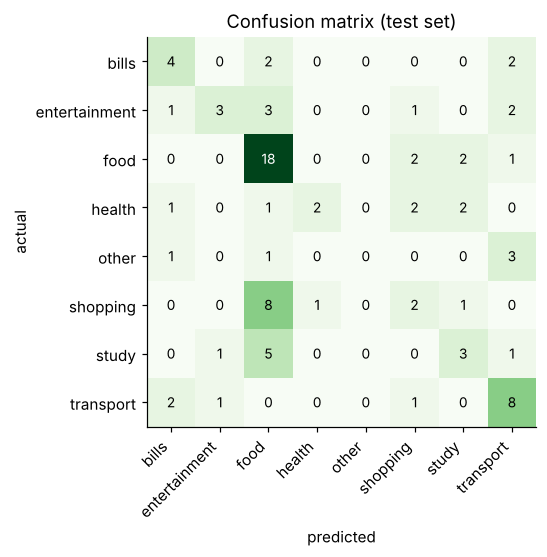

In [18]:
from sklearn.metrics import confusion_matrix

labels = sorted(df["category"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("predicted"); ax.set_ylabel("actual")
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Confusion matrix (test set)")

**عمود `food` مليان.** الموديل لما ما بيعرف، بيقول "أكل".

**ليش؟** كل مثال بالبيانات **شي مختلف**. لما الـ test فيه `dentist` والـ train فيه بس `طبيب اسنان` و `diş hekimi`،
ما في ولا حرف مشترك، فالموديل **ما عنده أي معلومة**، فبيرجع للـ **prior**: الفئة الأكثر شيوعاً (أكل).

**هل المشكلة بالخوارزمية؟** جربنا كمان Logistic Regression و Linear SVM (الخطوة 4 بالتفصيل): **كلهم بين 40% و 45%**.
لما كل الخوارزميات بتعطي نفس النتيجة الضعيفة، المشكلة **مش بالخوارزمية، بالبيانات**.

### 3.5 Learning curve: هل بيانات أكثر رح تساعد؟
منعطي الموديل 20%، 40%... 100% من البيانات، ومنشوف كيف بتتغير النتيجة:

  70 examples -> test F1 0.17
 140 examples -> test F1 0.24
 210 examples -> test F1 0.28
 280 examples -> test F1 0.31
 351 examples -> test F1 0.32


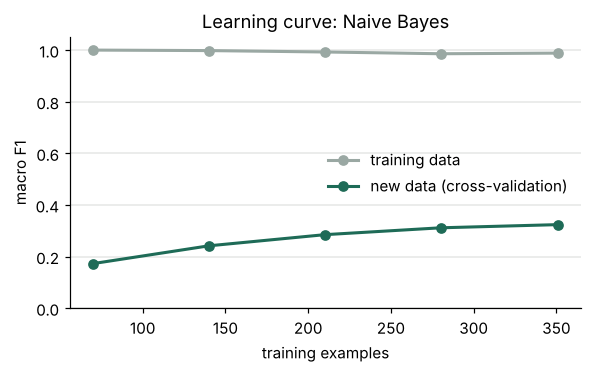

In [19]:
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.pipeline import make_pipeline

sizes, train_scores, test_scores = learning_curve(
    make_pipeline(CountVectorizer(analyzer=features), MultinomialNB()),
    df["description"], df["category"], cv=StratifiedKFold(5, shuffle=True, random_state=42),
    train_sizes=np.linspace(0.2, 1.0, 5), scoring="f1_macro", shuffle=True, random_state=0)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sizes, train_scores.mean(axis=1), "o-", color=MUTED, lw=2, label="training data")
ax.plot(sizes, test_scores.mean(axis=1), "o-", color=PINE, lw=2, label="new data (cross-validation)")
ax.set_ylim(0, 1.05); ax.set_xlabel("training examples"); ax.set_ylabel("macro F1")
ax.set_title("Learning curve: Naive Bayes"); ax.legend(frameon=False, loc="center right")
ax.grid(axis="y", color="#e5e7e6", lw=1)
for s, t in zip(sizes, test_scores.mean(axis=1)):
    print(f"{s:4d} examples -> test F1 {t:.2f}")

### التشخيص
| الملاحظة | المعنى (Week 3: Overfitting) |
|---|---|
| على بيانات التدريب ≈ **1.00** | الموديل **حافظ** الأمثلة |
| على بيانات جديدة ≈ **0.32** | ما **تعلّم** يعمّم |
| الفجوة كبيرة | **High variance (Overfitting)** |
| الخط الأخضر **لسا طالع** وما استقر | **بيانات أكثر = نتيجة أحسن** |

### خلاصة الخطوة 3
| ✅ | |
|---|---|
| Bayes' theorem، prior، likelihood | فهمناهم وحسبناهم بإيدنا |
| Laplace smoothing | حلّينا مشكلة الصفر |
| Log probabilities | حلّينا مشكلة الـ underflow |
| Naive Bayes من الصفر | **طابق scikit-learn 100%** |
| النتيجة 45% | **شخّصنا السبب: البيانات قليلة، مش الخوارزمية** |

**الدرس الأهم:** بالشغل الحقيقي، أغلب الوقت بيروح على **البيانات**، مش على اختيار الخوارزمية.
**الخطوة الجاية:** منكبّر البيانات، ومنشوف إذا التشخيص صح.

---
## الخطوة 4: بيانات أكثر 📈 (هل التشخيص صح؟)

الـ learning curve قال: **"بيانات أكثر رح تساعد"**. هلأ منختبر هالتوقع، متل أي فرضية علمية.

### من وين جت البيانات الجديدة؟
1. **من محمد** (طالب حقيقي، كلماته هو): "باص، تكسي، مترو، ترام = مواصلات · شاي، عصير، مي، خضار، فواكة = أكل · غاز، كهربا، نت، فواتير، عائدات = فواتير".
   هاد **أول بيانات حقيقية** عنا، وهو بالضبط "المنطق" اللي أي طالب بيعرفه.
2. **Round 2**: كملنا على نفس الفكرة: الكلمات اليومية لكل فئة، **ونفس المفهوم بالثلاث لغات** (ترام / tram / tramvay).

In [20]:
data = pd.read_csv("../data/expenses.csv")
print(data["source"].value_counts().to_string(), "\n")

# Duplicates AFTER normalizing: "Metro" and "metro", or "قهوة" and "قهوه", are the same
# example for the model. Step 1 only removed exact copies; now we know better.
data["normalized"] = data["description"].map(normalize)
exact = data.duplicated("description").sum()
after_norm = data.duplicated("normalized").sum()
print(f"exact duplicates: {exact}   ·   duplicates after normalize(): {after_norm}")

# Same text with two different labels would confuse the model: check there are none.
conflicts = data.groupby("normalized")["category"].nunique()
print("same text, different categories:", list(conflicts[conflicts > 1].index) or "none ✅")

data = data.drop_duplicates("normalized").reset_index(drop=True)
print(f"\nExamples now: {len(data)}  (round 1 had {len(df)})")

source
round2      609
round1      448
mohammed     14 

exact duplicates: 29   ·   duplicates after normalize(): 35
same text, different categories: none ✅

Examples now: 1036  (round 1 had 439)


Imbalance ratio: 3.6 : 1  (was 4.6 : 1)


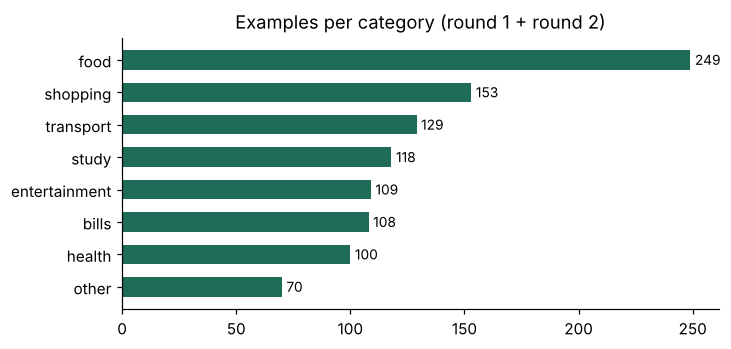

In [21]:
counts_all = data["category"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(counts_all.index[::-1], counts_all.values[::-1], color=PINE, height=0.6)
for y, v in enumerate(counts_all.values[::-1]):
    ax.text(v + 2, y, str(v), va="center", fontsize=9)
ax.set_title("Examples per category (round 1 + round 2)")
print(f"Imbalance ratio: {counts_all.max() / counts_all.min():.1f} : 1  (was 4.6 : 1)")

### المقارنة: نفس الموديل، نفس الطريقة، بيانات أكثر
منستخدم **Stratified 5-Fold Cross-Validation** (Week 7) بدل تقسيمة وحدة: النتيجة أثبت لأنه كل مثال بينجرب مرة.

In [22]:
from sklearn.model_selection import cross_val_predict

cv = StratifiedKFold(5, shuffle=True, random_state=42)
nb_pipeline = make_pipeline(CountVectorizer(analyzer=features), MultinomialNB())

rows = []
for name, subset in [("round 1 only", data[data["source"] == "round1"]), ("round 1 + 2", data)]:
    pred = cross_val_predict(nb_pipeline, subset["description"], subset["category"], cv=cv)
    rows.append({"data": name, "examples": len(subset),
                 "accuracy": accuracy_score(subset["category"], pred),
                 "macro F1": f1_score(subset["category"], pred, average="macro")})
print(pd.DataFrame(rows).round(3).to_string(index=False))

        data  examples  accuracy  macro F1
round 1 only       436     0.413     0.317
 round 1 + 2      1036     0.499     0.454


**ملاحظة عدالة المقارنة:** الرقمين فوق منجربهم على **أسئلة مختلفة** (بيانات round 2 دخلت بالـ test كمان).
فخلينا نعمل مقارنة أعدل: **نفس أسئلة round 1 بالضبط**، مرة بدون round 2 ومرة معها بالتدريب:

In [23]:
round1 = data[data["source"] == "round1"].reset_index(drop=True)
extra = data[data["source"] != "round1"]

before, after = [], []
for train_idx, test_idx in cv.split(round1["description"], round1["category"]):
    test = round1.iloc[test_idx]
    small = NaiveBayes().fit(round1["description"].iloc[train_idx], round1["category"].iloc[train_idx])
    big = NaiveBayes().fit(pd.concat([round1["description"].iloc[train_idx], extra["description"]]),
                           pd.concat([round1["category"].iloc[train_idx], extra["category"]]))
    before.append(accuracy_score(test["category"], [small.predict(t).label for t in test["description"]]))
    after.append(accuracy_score(test["category"], [big.predict(t).label for t in test["description"]]))
print(f"Same round-1 questions:  without round 2 -> {np.mean(before):.1%}   with round 2 -> {np.mean(after):.1%}")

Same round-1 questions:  without round 2 -> 41.3%   with round 2 -> 55.3%


['165: 0.27', '331: 0.32', '496: 0.37', '662: 0.41', '828: 0.45']


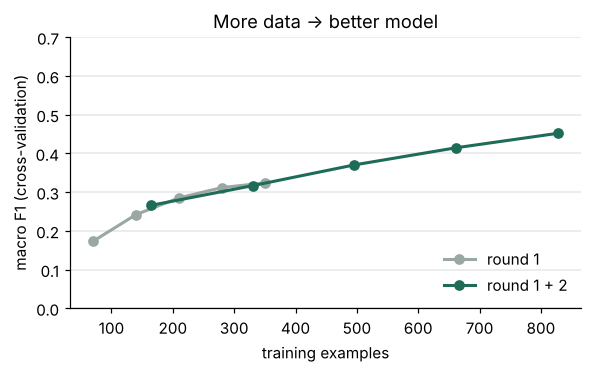

In [24]:
sizes2, _, test_scores2 = learning_curve(
    nb_pipeline, data["description"], data["category"], cv=cv,
    train_sizes=np.linspace(0.2, 1.0, 5), scoring="f1_macro", shuffle=True, random_state=0)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sizes, test_scores.mean(axis=1), "o-", color=MUTED, lw=2, label="round 1")
ax.plot(sizes2, test_scores2.mean(axis=1), "o-", color=PINE, lw=2, label="round 1 + 2")
ax.set_ylim(0, 0.7); ax.set_xlabel("training examples"); ax.set_ylabel("macro F1 (cross-validation)")
ax.set_title("More data -> better model"); ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", color="#e5e7e6", lw=1)
print([f"{s}: {v:.2f}" for s, v in zip(sizes2, test_scores2.mean(axis=1))])

**التوقع طلع صح:** الخط الأخضر بيكمّل من وين وقف الرمادي، ولسا طالع. يعني بيانات أكثر (من مستخدمين حقيقيين) رح تحسّنه كمان.

### الامتحان الحقيقي: كلمات بيكتبها طالب
الـ cross-validation بيقيس "مفاهيم ما شافها أبداً" (أصعب امتحان ممكن). بس بالاستخدام الحقيقي، الطالب **بيكرر نفس الكلمات** (قهوة، مترو، كيرا كل شهر).

In [25]:
final_nb = NaiveBayes().fit(data["description"], data["category"])
checks = ["ترام", "tramvay bileti", "shawrma", "dentist", "su faturası", "Netflix", "شحن رصيد",
          "kira", "spor salonu üyelik", "electricity bill october", "نرجيلة مع الشباب", "birthday cake"]
for text in checks:
    p = final_nb.predict(text)
    print(f"{text:26} -> {p.label:13} ({p.confidence:.0%})")

ترام                       -> transport     (100%)
tramvay bileti             -> transport     (100%)
shawrma                    -> food          (100%)
dentist                    -> health        (100%)
su faturası                -> bills         (100%)
Netflix                    -> entertainment (100%)
شحن رصيد                   -> bills         (100%)
kira                       -> bills         (100%)
spor salonu üyelik         -> health        (100%)
electricity bill october   -> bills         (100%)
نرجيلة مع الشباب           -> entertainment (100%)
birthday cake              -> transport     (95%)


كلها صح... إلا **`birthday cake` → transport بثقة 95%** ❌

**ليش؟** `cake` موجودة بالأكل، بس `birthday` ما شافها، فقطع حروفها (` bi`، `bir`، `day`...) لعبت الدور الأكبر،
وبالصدفة شبيهة بقطع من أمثلة المواصلات. وNaive Bayes **بيعدّ كل قطعة كدليل مستقل**، فبيبالغ بالثقة.

هاد بيفتح سؤال منطقي: **هل في موديل أحسن من Naive Bayes لهالنوع من البيانات؟** هاد اللي رح نجاوب عليه بالخطوة الجاية.

### خلاصة الخطوة 4
| | قبل | بعد |
|---|---|---|
| عدد الأمثلة | 436 | **1036** |
| Macro F1 (cross-validation) | 0.32 | **0.45** |
| نفس أسئلة round 1 | ~41% | **~55%** |
| كلمات يومية لطالب | ❌ كتير غلط | ✅ أغلبها صح |

**الدرس:** التشخيص (learning curve) قال "المشكلة بالبيانات"، وطلع صح. **قبل ما تغيّر الموديل، افهم ليش هو ضعيف.**

---
## الخطوة 5: مقارنة الموديلات ⚖️ (Week 3, 5, 7, 8)

نفس طريقة مشروعك: **نفس البيانات، نفس الـ features، نفس الـ Stratified 5-Fold**، ومنغيّر الموديل بس. هيك المقارنة عادلة.

للموديلات غير Naive Bayes منستخدم **TF-IDF** (من الخطوة 2) مع `sublinear_tf=True` (يعني `1 + log(tf)`: كلمة متكررة 3 مرات ما بتصير أهم بـ 3 أضعاف).

In [26]:
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X_all, y_all = data["description"], data["category"]
tfidf = lambda: TfidfVectorizer(analyzer=features, sublinear_tf=True)

candidates = {
    "Naive Bayes (ours = sklearn)": make_pipeline(CountVectorizer(analyzer=features), MultinomialNB()),
    "Complement NB":       make_pipeline(tfidf(), ComplementNB(alpha=0.3)),
    "Logistic Regression": make_pipeline(tfidf(), LogisticRegression(C=10, max_iter=3000)),
    "Linear SVM":          make_pipeline(tfidf(), LinearSVC(C=1)),
    "SVM (RBF kernel)":    make_pipeline(tfidf(), SVC(C=10)),
    "KNN (k=5, cosine)":   make_pipeline(tfidf(), KNeighborsClassifier(5, metric="cosine")),
    "Decision Tree":       make_pipeline(tfidf(), DecisionTreeClassifier(random_state=0)),
    "Random Forest":       make_pipeline(tfidf(), RandomForestClassifier(300, random_state=0, n_jobs=-1)),
}

results = []
for name, pipeline in candidates.items():
    r = cross_validate(pipeline, X_all, y_all, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
    results.append({"model": name, "accuracy": r["test_accuracy"].mean(),
                    "macro F1": r["test_f1_macro"].mean(), "± (std)": r["test_f1_macro"].std(),
                    "train F1": r["train_f1_macro"].mean(), "fit time (s)": r["fit_time"].mean()})
results = pd.DataFrame(results).sort_values("macro F1", ascending=False)
print(results.round(3).to_string(index=False))

                       model  accuracy  macro F1  ± (std)  train F1  fit time (s)
                  Linear SVM     0.520     0.486    0.049     1.000         0.069
         Logistic Regression     0.517     0.484    0.047     1.000         1.479
               Complement NB     0.507     0.478    0.032     0.988         0.099
            SVM (RBF kernel)     0.508     0.472    0.028     1.000         0.271
Naive Bayes (ours = sklearn)     0.499     0.453    0.041     0.974         0.060
               Random Forest     0.437     0.373    0.033     1.000         2.204
           KNN (k=5, cosine)     0.406     0.362    0.039     0.601         0.049
               Decision Tree     0.335     0.308    0.040     1.000         0.355


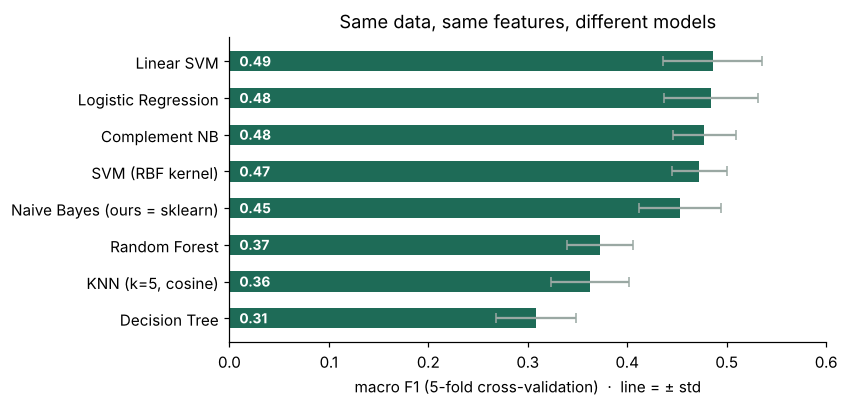

In [27]:
order = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(order["model"], order["macro F1"], xerr=order["± (std)"], color=PINE, height=0.55,
        error_kw={"ecolor": MUTED, "elinewidth": 1.5, "capsize": 3})
for y, v in enumerate(order["macro F1"]):
    ax.text(0.01, y, f"{v:.2f}", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_xlim(0, 0.6); ax.set_xlabel("macro F1 (5-fold cross-validation)  ·  line = ± std")
ax.set_title("Same data, same features, different models")

### شو منقرأ من الجدول؟
| الملاحظة | التفسير (من محاضراتك) |
|---|---|
| الموديلات **الخطية** فوق (SVM، LogReg، NB) | النص بعد TF-IDF = آلاف الأعمدة وأغلبها أصفار، والموديلات الخطية ممتازة بهيك بيانات |
| **KNN** ضعيف | **Curse of dimensionality** (Week 12): مع 9,000 بُعد، المسافات بتفقد معناها |
| **Decision Tree** الأسوأ، و train F1 = 1.00 | **Overfitting** (Week 5): بيحفظ، وكل split على قطعة حروف وحدة |
| **Random Forest** أحسن من Tree بكتير | **Bagging** بيخفف الـ variance (Week 7)، بس الأشجار ما بتناسب النص المتفرّق |
| الفرق بين الأول و NB تبعنا ≈ **0.03** | **أصغر من الـ ±** (0.05)! يعني إحصائياً متقاربين جداً |

**الدرس:** "الموديل الأحسن" بالجدول مش دايماً أحسن فعلاً. لازم تشوف الـ **±**. بس في سؤال أهم من الدقة...

### 5.2 السؤال الأهم: هل الموديل **بيعرف لما ما بيعرف**؟
الموقع رح يستخدم الموديل هيك:
- إذا **متأكد** ← بيختار الفئة لحاله ✨
- إذا **مش متأكد** ← بيترك الطالب يختار

فبدنا موديل ثقته **صادقة**: لما يقول 80%، يكون صح بحوالي 80% من المرات. هاد اسمه **Calibration**.

In [28]:
from sklearn.metrics import log_loss

classes = np.array(sorted(y_all.unique()))
compare = {
    "Naive Bayes": candidates["Naive Bayes (ours = sklearn)"],
    "Logistic Regression": candidates["Logistic Regression"],
}
coverage_rows, curves = [], {}
for name, pipeline in compare.items():
    probs = cross_val_predict(pipeline, X_all, y_all, cv=cv, method="predict_proba")
    confidence, correct = probs.max(axis=1), classes[probs.argmax(axis=1)] == y_all.values
    print(f"{name:20} log loss = {log_loss(y_all, probs, labels=classes):.2f}   (lower = more honest probabilities)")
    curves[name] = (confidence, correct)
    for t in (0.5, 0.6, 0.7, 0.8, 0.9):
        chosen = confidence >= t
        coverage_rows.append({"model": name, "when confidence ≥": t,
                              "% of expenses": chosen.mean(), "right": correct[chosen].mean()})
table = pd.DataFrame(coverage_rows)
print()
print(table.pivot(index="when confidence ≥", columns="model", values="right").map("{:.0%}".format).to_string())

Naive Bayes          log loss = 3.01   (lower = more honest probabilities)
Logistic Regression  log loss = 1.42   (lower = more honest probabilities)

model             Logistic Regression Naive Bayes
when confidence ≥                                
0.5                               78%         54%
0.6                               84%         56%
0.7                               90%         58%
0.8                               96%         61%
0.9                              100%         66%


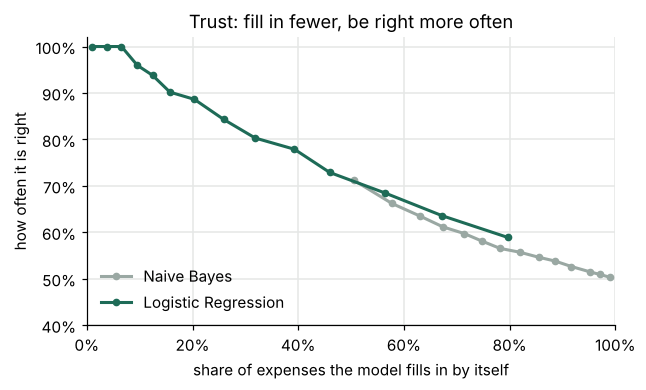

In [29]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for name, color in (("Naive Bayes", MUTED), ("Logistic Regression", PINE)):
    confidence, correct = curves[name]
    thresholds = np.linspace(0.3, 0.95, 14)
    xs = [(confidence >= t).mean() for t in thresholds]
    ys = [correct[confidence >= t].mean() for t in thresholds]
    ax.plot(xs, ys, "o-", color=color, lw=2, ms=4, label=name)
ax.set_xlabel("share of expenses the model fills in by itself")
ax.set_ylabel("how often it is right")
ax.set_ylim(0.4, 1.02); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, loc="lower left"); ax.grid(color="#e5e7e6", lw=1)
ax.set_title("Trust: fill in fewer, be right more often")

### الفرق الحقيقي
| | Naive Bayes | Logistic Regression |
|---|---|---|
| لما يقول "**≥ 90%** متأكد" | صح بـ **66%** بس ❌ | صح بـ **100%** ✅ |
| لما يقول "**≥ 60%**" | صح بـ 56% | صح بـ **84%** ✅ |
| Log loss | 3.01 | **1.42** |
| `birthday cake` | transport بثقة **95%** | transport بثقة **42%** (يعني "مش متأكد") |

**بالرسم:** لما الموديلين بيملوا **نفس النسبة** من المصاريف، دقتهم متقاربة (يعني **ترتيب** الثقة عند NB مفيد، متل ما قلنا بالخطوة 3).
الفرق إنه **NB ما بيوصل للجزء اليسار من الرسم**: أرقامه كلها عالية، فحتى لو قلنا "بس إذا ≥ 90%"، بيملا 58% من المصاريف وبيصيب بـ 66% بس.
أما LogReg بيقدر يقول "هدول الـ 10% أنا متأكد منهم" ويكون صح بـ 96%. يعني **أرقام الثقة تبعه بنقدر نستخدمها مباشرة كـ threshold** بالموقع.

ليش؟ تذكّر الخطوة 3: NB بيفترض الـ features **مستقلة**، بس ` sh` و `sha` و `shaw` جايين من نفس الكلمة، فبيعدّ نفس الدليل كذا مرة.
Logistic Regression **ما بيفترض الاستقلال**: بيتعلم **وزن** لكل feature مع بعض، فإذا قطع كتير بتعني نفس الشي، بيوزعلها الوزن.

### القرار
| | |
|---|---|
| دقة (macro F1) | متقاربين، LogReg أعلى بشوي |
| **ثقة صادقة** | **LogReg بفرق كبير** ← وهاد اللي بيحتاجه الموقع |
| بيقدر يتعلم من تصحيح واحد | NB أسهل (عدّ)، بس LogReg ممكن كمان (خطوة gradient وحدة) |

**→ Logistic Regression** هو الموديل الأساسي. والخطوة الجاية: **منبنيه من الصفر** بـ **Gradient Descent** (Week 2) و **Sigmoid/Softmax** (Week 3) و **L2 Regularization** (Week 9)، متل ما عملنا مع Naive Bayes.

**وNaive Bayes ما رحنا عليه ببلاش:** فهمنا Bayes، وبنينا أول موديل، وكشفنا مشكلة البيانات، وعرفنا ليش الثقة مهمة.

---
## الخطوة 6: Logistic Regression من الصفر 🧮 (Week 2, 3, 9)

بالخطوة 5 اخترنا Logistic Regression لأنه **ثقته صادقة**. هلق منبنيه بإيدنا، متل ما عملنا مع Naive Bayes.

### الفكرة بثلاث جمل
1. لكل فئة في **وزن** لكل feature. مثلاً وزن `" taxi"` عند transport كبير وموجب، وعند food سالب.
2. **score** الفئة = مجموع (قيمة الـ feature × وزنها) + bias:  $z_c = b_c + \sum_f x_f \, W_{f,c}$
3. **Softmax** (Week 3) بيحوّل الـ scores لاحتمالات مجموعها 1:  $P(c \mid x) = \dfrac{e^{z_c}}{\sum_k e^{z_k}}$

بـ Week 3 شفت **Sigmoid** لفئتين: $\sigma(z) = \frac{1}{1+e^{-z}}$. Softmax هو نفس الفكرة بس لأكتر من فئتين (لو عنا فئتين بس، Softmax = Sigmoid بالضبط).

softmax([2, 0])[0] = 0.8808    sigmoid(2) = 0.8808
  food       z =  -0.8   ->   P = 0.04
  transport  z =   2.4   ->   P = 0.88
  bills      z =   0.1   ->   P = 0.09


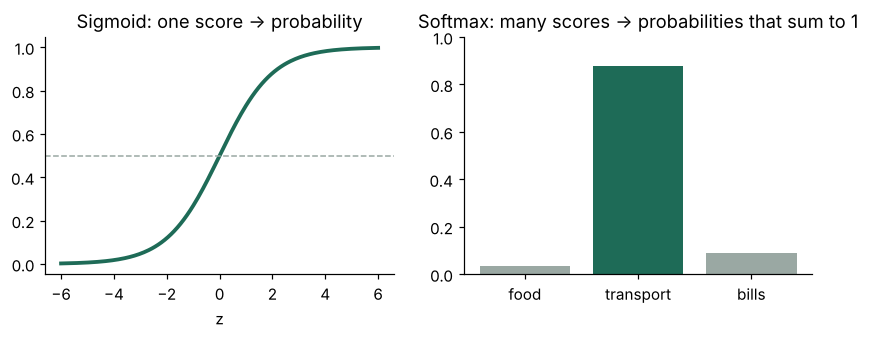

In [30]:
import numpy as np

def softmax(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())          # minus the max: same answer, but exp() never overflows
    return e / e.sum()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Softmax with two classes is the sigmoid of the difference:
print("softmax([2, 0])[0] =", softmax([2, 0])[0].round(4), "   sigmoid(2) =", sigmoid(2).round(4))

# Three made-up scores for "taxi":
z = {"food": -0.8, "transport": 2.4, "bills": 0.1}
for label, p in zip(z, softmax(list(z.values()))):
    print(f"  {label:<10} z = {z[label]:>5}   ->   P = {p:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
t = np.linspace(-6, 6, 200)
axes[0].plot(t, sigmoid(t), color=PINE, lw=2.5); axes[0].axhline(0.5, color=MUTED, ls="--", lw=1)
axes[0].set_title("Sigmoid: one score -> probability"); axes[0].set_xlabel("z")
axes[1].bar(list(z), softmax(list(z.values())), color=[MUTED, PINE, MUTED])
axes[1].set_title("Softmax: many scores -> probabilities that sum to 1"); axes[1].set_ylim(0, 1)

### كيف بيتعلم الأوزان؟ Loss + Gradient Descent (Week 2)

**الـ Loss (Cross-Entropy):** لكل مثال، قديش أعطى الموديل احتمال **للجواب الصح**؟ إذا 0.9 ← loss صغير ($-\log 0.9 = 0.1$). إذا 0.05 ← loss كبير ($-\log 0.05 = 3$).

$$J(W, b) = -\frac{1}{n}\sum_i \log P(y_i \mid x_i) \;+\; \frac{\lambda}{2}\lVert W\rVert^2$$

الجزء التاني هو **L2 Regularization** (Week 9): عقوبة على الأوزان الكبيرة، حتى ما يحفظ الموديل البيانات (overfitting).

**الـ Gradient** (الاشتقاق طلع حلو كتير):
$$\frac{\partial J}{\partial W} = \frac{1}{n} X^\top (P - Y) + \lambda W \qquad \frac{\partial J}{\partial b} = \text{mean}(P - Y)$$

$P - Y$ = **الغلط**: الاحتمال اللي أعطاه ناقص الجواب الصح (one-hot). إذا قال transport = 0.3 والجواب transport، الغلط = −0.7، فبيرفع وزن features هاد المثال عند transport.

**Gradient Descent:** $W \leftarrow W - \alpha \cdot \frac{\partial J}{\partial W}$ ، ومنكرر آلاف المرات. ($\alpha$ = learning rate)

الكود الحقيقي بـ `ml/train_categorizer.py`، وهاد قلبه (5 أسطر):
```python
for i in range(iterations):
    P = softmax(X @ W + b)                        # predict
    W -= lr * (X.T @ (P - Y) / n + lam * W)       # step downhill
    b -= lr * (P - Y).mean(axis=0)                # the bias is not regularized
```
**ملاحظة:** `X` هي **sparse matrix** (12,000 عمود وأغلبها أصفار). بنسخة dense كان التدريب أبطأ بكتير.

X_train: (828, 10355) · only 0.21% of the cells are not zero
lr =  1: loss after 1500 steps = 0.7511
lr = 30: loss after 1500 steps = 0.2929
lr = 100: loss after 1500 steps = 0.3518


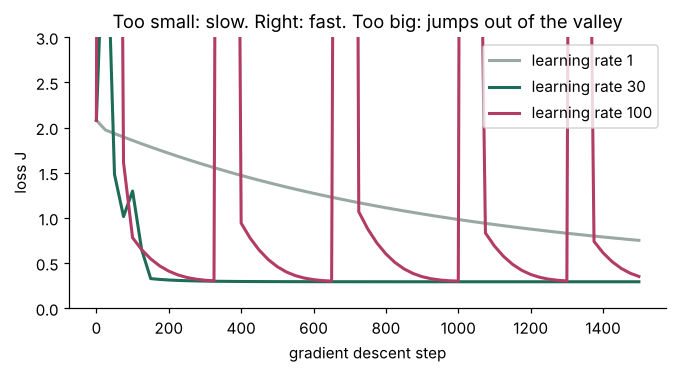

In [31]:
sys.path.insert(0, "..")                       # ml/ folder: the training script
from train_categorizer import TfidfVocabulary, to_matrix, gradient_descent, fit
from app.ml.logistic import NGRAM_SIZES

train, test = train_test_split(data, test_size=0.2, stratify=data["category"], random_state=42)
vocabulary = TfidfVocabulary().fit(train["description"])     # the API's own TF-IDF code
X_train = to_matrix(vocabulary, list(train["description"]))
X_test = to_matrix(vocabulary, list(test["description"]))
labels = sorted(data["category"].unique())
print("X_train:", X_train.shape, f"· only {X_train.nnz / np.prod(X_train.shape):.2%} of the cells are not zero")

# Week 2: the learning rate decides everything
curves = {}
for lr in (1, 30, 100):
    _, _, history = gradient_descent(X_train, train["category"], labels, C=30, lr=lr, iterations=1500, every=25)
    curves[lr] = history
    print(f"lr = {lr:>2}: loss after 1500 steps = {history[-1][1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
for lr, color in zip(curves, [MUTED, PINE, BERRY]):
    steps, losses = zip(*curves[lr])
    ax.plot(steps, losses, color=color, lw=2, label=f"learning rate {lr}")
ax.set_ylim(0, 3); ax.set_xlabel("gradient descent step"); ax.set_ylabel("loss J"); ax.legend()
ax.set_title("Too small: slow. Right: fast. Too big: jumps out of the valley")

### نفس اللي بـ Week 2 بالضبط
| learning rate | شو صار |
|---|---|
| **1** (صغير) | بينزل صح بس **ببطء**، بعد 1500 خطوة لسا بعيد |
| **30** (مناسب) | بينزل بسرعة وبيستقر |
| **100** (كبير) | الخطوة أكبر من الوادي: كل فترة **بيقفز لفوق** (الـ spikes) وبيرجع ينزل، وما بيستقر |

جربت كمان: 40 بيشتغل، بس من **60 وطالع** بتبلش القفزات. يعني الحد قريب من 50، فاخترنا **30**: سريع، وبعيد عن الحد بمسافة أمان (لأنه لما تكبر البيانات، الحد ممكن يتحرك). 3000 خطوة ≈ 8 ثواني.

### هل الموديل تبعنا صح؟ منقارنه مع scikit-learn
scikit-learn بيستخدم `C` بدل $\lambda$. العلاقة: $\lambda = \frac{1}{C \cdot n}$. (C كبير = regularization أقل)

In [32]:
from sklearn.linear_model import LogisticRegression

ours, _ = fit(train["description"], train["category"], C=30, lr=30, iterations=3000)
sk = LogisticRegression(C=30, max_iter=10000, tol=1e-10).fit(X_train, train["category"])

P_ours = np.array([[ours.predict(t).probabilities[c] for c in sk.classes_] for t in test["description"]])
P_sk = sk.predict_proba(X_test)
print(f"largest probability difference: {np.abs(P_ours - P_sk).max():.4f}")
print(f"same answer:                    {np.mean(P_ours.argmax(1) == P_sk.argmax(1)):.0%}")
print(f"largest weight difference:      {np.abs(np.array([ours.weights[f] for f in vocabulary.idf]) - sk.coef_.T).max():.4f}")

largest probability difference: 0.0019
same answer:                    100%
largest weight difference:      0.0043


✅ **نفس الموديل.** الفرق الصغير لأنه gradient descent وقف بعد 3000 خطوة، و scikit-learn بيستخدم طريقة أذكى (L-BFGS) بتوصل للقاع بخطوات أقل. بس الاتنين بيدوروا على **نفس القاع** لنفس الـ loss.

---
### Hyperparameter Tuning: GridSearchCV (Week 9)
عنا شغلتين ما بيتعلمهم الموديل لحاله (**hyperparameters**):
- **C**: قديش منعاقب الأوزان الكبيرة
- **أطوال قطع الحروف**: `(2,3,4)` يعني قطع من 2 و3 و4 حروف

**GridSearchCV** بيجرب **كل التركيبات** (6 × 4 = 24)، وكل وحدة بـ 5-fold cross-validation = **120 تدريب**. (هون منستخدم scikit-learn لأنه أسرع، وأثبتنا فوق إنه نفس الموديل)

macro F1 (higher is better)
 param_model__C  0.3    1.0    3.0    10.0   30.0   100.0
sizes                                                   
(2, 3)          0.150  0.371  0.444  0.470  0.479  0.483
(2, 3, 4)       0.139  0.370  0.464  0.484  0.486  0.488
(2, 3, 4, 5)    0.135  0.365  0.471  0.483  0.490  0.485
(3, 4, 5)       0.134  0.352  0.481  0.500  0.506  0.508 

log loss (lower is better)
 param_model__C  0.3    1.0    3.0    10.0   30.0   100.0
sizes                                                   
(2, 3)          1.869  1.694  1.538  1.463  1.480  1.560
(2, 3, 4)       1.870  1.688  1.518  1.424  1.419  1.473
(2, 3, 4, 5)    1.872  1.689  1.514  1.413  1.399  1.443
(3, 4, 5)       1.876  1.693  1.511  1.402  1.379  1.413


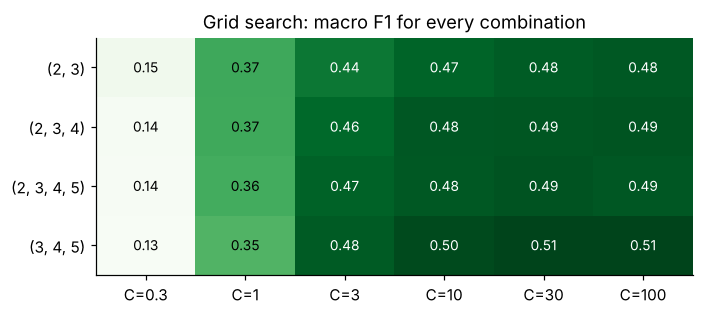

In [33]:
from functools import partial
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)), ("model", LogisticRegression(max_iter=3000))])
SIZES = [(2, 3), (2, 3, 4), (2, 3, 4, 5), (3, 4, 5)]
grid = GridSearchCV(
    pipeline,
    {"tfidf__analyzer": [partial(features, sizes=s) for s in SIZES], "model__C": [0.3, 1, 3, 10, 30, 100]},
    cv=cv, scoring={"f1": "f1_macro", "log_loss": "neg_log_loss"}, refit="f1", n_jobs=-1,
).fit(data["description"], data["category"])

g = pd.DataFrame(grid.cv_results_)
g["sizes"] = g["param_tfidf__analyzer"].map(lambda a: str(a.keywords["sizes"]))
f1_table = g.pivot_table(index="sizes", columns="param_model__C", values="mean_test_f1")
print("macro F1 (higher is better)\n", f1_table.round(3), "\n")
print("log loss (lower is better)\n", (-g.pivot_table(index="sizes", columns="param_model__C", values="mean_test_log_loss")).round(3))

fig, ax = plt.subplots(figsize=(7, 2.8))
im = ax.imshow(f1_table.values, cmap="Greens", aspect="auto")
ax.set_xticks(range(len(f1_table.columns)), [f"C={c:g}" for c in f1_table.columns])
ax.set_yticks(range(len(f1_table.index)), f1_table.index)
for (i, j), v in np.ndenumerate(f1_table.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.4 else "black", fontsize=9)
ax.set_title("Grid search: macro F1 for every combination")

### شو منقرأ؟
| الملاحظة | التفسير |
|---|---|
| **C صغير (0.3، 1) سيء جداً** | Regularization قوي كتير ← الأوزان شبه صفر ← **Underfitting** (high bias) |
| من C = 10 وطالع، شبه ثابت | الموديل وصل لحده مع هالبيانات |
| **C = 100**: الـ F1 نفسه تقريباً، بس الـ **log loss أسوأ** | regularization قليل ← أوزان كبيرة ← **ثقة زيادة** (متل NB!) |
| قطع **(3, 4, 5)** أحسن من (2, 3, 4) | قطعة من حرفين (`ta`) موجودة بكلمات كتير، فما بتقول شي. 5 حروف (`taksi`) أوضح |

**القرار: قطع (3, 4, 5) و C = 30** (أحسن log loss، و F1 من الأعلى).

⚠️ **بصراحة:** الفرق بين أحسن تركيبة و (2,3,4) مع C=10 هو ≈ 0.02، والـ ± بالـ cross-validation ≈ 0.04. يعني التحسن **مش أكيد إحصائياً**. الـ tuning ساعد شوي، بس **البيانات لسا هي الحد** (متل ما قال الـ learning curve بالخطوة 3).

In [34]:
from app.ml.logistic import SoftmaxRegression
from pathlib import Path

artifact = Path("../../backend/app/ml/artifacts/categorizer.json")   # made by: python ml/train_categorizer.py
model = SoftmaxRegression.load(artifact)
print(f"{artifact.name}: {artifact.stat().st_size / 1024:.0f} KB, {len(model.weights):,} features, "
      f"pieces of {model.vocabulary.sizes} letters\n")
for text in ["taxi", "شاي", "aidat", "netflx", "kitapçı", "تكسي للجامعة", "birthday cake"]:
    p = model.predict(text)
    print(f"  {text:<14} -> {p.label:<13} {p.confidence:.0%}")

categorizer.json: 1410 KB, 11,960 features, pieces of (3, 4, 5) letters

  taxi           -> transport     95%
  شاي            -> food          92%
  aidat          -> bills         91%
  netflx         -> entertainment 93%
  kitapçı        -> study         89%
  تكسي للجامعة   -> transport     92%
  birthday cake  -> transport     38%


### الملخص
| | |
|---|---|
| الموديل | Softmax Regression، **مكتوب من الصفر**، ونفس scikit-learn |
| التدريب | `ml/train_categorizer.py`: Gradient Descent بـ numpy على sparse matrix |
| بالموقع | `backend/app/ml/logistic.py`: Python عادي + ملف JSON (بدون numpy، بدون pickle) |
| نفس تجهيز النص | التدريب بيستخدم **نفس** `TfidfVocabulary` تبع الـ API ← ما في training-serving skew |
| الـ hyperparameters | C = 30، قطع (3,4,5)، اخترناهم بـ GridSearchCV |

`birthday cake` لسا transport بس بثقة **38%**، يعني الموديل بيعرف إنه **مش متأكد**. بالموقع ما رح نقترح فئة إلا إذا الثقة ≥ 60% تقريباً.

**الخطوة الجاية (7): ليش اختار هيك؟** منفتح الموديل ومنشوف أهم الأوزان لكل فئة (Explainability، Week 10).